# Hand Detection: how many hands does MediaPipe really find?

**The question:** MediaPipe Hands is the go-to tool for hand tracking: three lines of code draw 21 landmarks on a hand in a webcam feed, and the demo looks magical when your hand is held up close to the camera. The legacy script here wraps it in a small class and prints the position of the thumb tip. *But how many real hands, in ordinary photographs, does it actually find? What decides whether a hand is found? Can a simple trick find the missed ones, and when a hand is found, how accurate are its landmarks?* We test on **846 hand annotations** (426 right hands, 420 left) from **461 photographs** with 21 hand-labelled keypoints each.

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit: the photographs and the hands in them
4. Hypotheses and why we chose each test
5. The tools
6. H1: how many hands are found?
7. H2: does the size of the hand decide?
8. H3: can zooming in find the missed hands?
9. H4: lowering the bar, or zooming in?
10. H5: how accurate are the landmarks?
11. Takeaways
12. Limitations

**Run it:** `uv run jupyter lab CV/hand-detection/hand_detection.ipynb`, or *Run All* in any Jupyter. The photographs (about 180 MB) and the 8 MB hand model download themselves on the first run; it takes about 10 minutes on a CPU. MediaPipe needs the system library `libgles2` (`sudo apt install libgles2` on Debian or Ubuntu).

## 1. 💡 The simple analogy

Imagine looking for **a friend's hand in a crowd photo** through a small square window.

- If the hand fills the window, you spot it at once, and you can even point to each finger.
- If the hand is a **tiny smudge**, the window shows you almost nothing: you need to **step closer and look at one part of the picture at a time**.
- You can also **lower your standards** ("anything that might be a hand") and find more, but you will also point at gloves, paws and shadows.
- And once you have found a hand, **pointing at each fingertip** is harder than pointing at the knuckles.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed, the match rule and the size bands keeps the notebook reproducible and avoids "magic numbers". A detection counts as having **found** a hand when the box around its landmarks overlaps the box around the hand-labelled keypoints by an **intersection over union (IoU) of at least 0.5**. "Hand size" means the longer side of the hand's box as a share of the longer side of the photograph.

In [1]:
# ruff: noqa: E402 (the settings below must come before the imports that read them)
import os
import warnings

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore", message="IProgress not found")
import contextlib
import json
import sys
import time
import urllib.request
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from huggingface_hub import snapshot_download
from huggingface_hub.utils import logging as hub_logging
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision
from scipy import stats
from statsmodels.stats.contingency_tables import mcnemar

hub_logging.set_verbosity_error()

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
SEED = 365
IOU_MATCH = 0.5  # a detection finds a hand if its landmark box overlaps the true hand by this much
N_BOOTSTRAP = 2_000
SIZE_BINS = [0, 0.05, 0.08, 0.12, 1.0]  # hand size as a share of the image's longer side
SIZE_NAMES = ["under 5%", "5-8%", "8-12%", "over 12%"]
TILE_SETTINGS = {"2x2 tiles": (2, 0.6), "3x3 tiles": (3, 0.45)}  # (tiles per side, tile size)
THRESHOLDS = [0.1, 0.3, 0.5, 0.7, 0.9]
MODEL_URL = (
    "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/"
    "hand_landmarker.task"
)
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if float(p) < 1e-300 else f"{float(p):.1e}"

## 3. Audit: the photographs and the hands in them

*What:* the data are the 846 hand annotations of the CMU hand-keypoint test set (Simon et al., 2017), hosted on Hugging Face. They come from everyday photographs (MPII Human Pose) and sign-language video frames, with **21 manually placed keypoints per hand**. Most photographs hold two annotated hands. *Why:* real photographs, with hand-placed ground truth, tell us what a webcam demo can't: how often the tool fails.

> **Problems in the legacy script this replaces:** it used `mp.solutions.hands`, which **no longer exists** in current MediaPipe (the script stops with an `AttributeError`); it needed a live webcam, so it never measured anything; it printed only one landmark; and it left the confidence settings commented out, so nobody could tell what was being asked of the model.

In [2]:
if not (DATA_DIR / "hk" / "samples.json").exists():
    snapshot_download(
        "Voxel51/hand-keypoints",
        repo_type="dataset",
        local_dir=DATA_DIR / "hk",
        allow_patterns=["*.json", "*.jpg"],
    )
if not (DATA_DIR / "hand_landmarker.task").exists():
    urllib.request.urlretrieve(MODEL_URL, DATA_DIR / "hand_landmarker.task")

samples = json.loads((DATA_DIR / "hk" / "samples.json").read_text())["samples"]
rows = []
for s in samples:
    side = "right" if s.get("right_hand") else "left"
    path = DATA_DIR / "hk" / s["filepath"]
    height, width = cv2.imread(str(path)).shape[:2]
    pts = np.array(s[f"{side}_hand"]["keypoints"][0]["points"]) * [width, height]
    box = np.r_[pts.min(0), pts.max(0)]
    rows.append(
        {
            "path": path,
            "image": path.stem[:-2],
            "side": side,
            "width": width,
            "height": height,
            "pts": pts,
            "box": box,
            "size": max(np.ptp(pts[:, 0]), np.ptp(pts[:, 1])) / max(width, height),
        }
    )
hands = pd.DataFrame(rows)
hands["size band"] = pd.cut(hands["size"], SIZE_BINS, labels=SIZE_NAMES)
hands["cluster"] = pd.factorize(hands["image"])[0]
print(
    f"{len(hands)} labelled hands in {hands['image'].nunique()} images "
    f"({(hands['side'] == 'left').sum()} left, {(hands['side'] == 'right').sum()} right)"
)
print(
    "Image sizes:",
    ", ".join(
        f"{w}x{h}" for w, h in hands[["width", "height"]].drop_duplicates().itertuples(False)
    ),
)
q = hands["size"].quantile([0, 0.1, 0.5, 0.9, 1]) * 100
print(
    "Hand size as a share of the image's longer side: min {:.1f}%, 10th {:.1f}%, median {:.1f}%, "
    "90th {:.1f}%, max {:.1f}%".format(*q)
)
print(
    "Hands per size band:",
    ", ".join(f"{k} {v}" for k, v in hands["size band"].value_counts().reindex(SIZE_NAMES).items()),
)

846 labelled hands in 461 images (420 left, 426 right)
Image sizes: 1920x1080, 400x300, 1280x720, 720x576, 1272x720, 720x408, 1440x1080, 854x480, 1916x1080
Hand size as a share of the image's longer side: min 2.1%, 10th 4.0%, median 8.7%, 90th 13.1%, max 17.4%
Hands per size band: under 5% 176, 5-8% 217, 8-12% 280, over 12% 173


**How to read this:**

- **846 labelled hands in 461 photographs** (420 left, 426 right), most photographs showing two hands. Hands from the same photograph are not independent, so every interval below **resamples photographs, not hands**.
- **These hands are small, as in real scenes:** the median hand is **8.7%** of the photograph's longer side, the smallest 2.1% and the largest 17.4%. A webcam demo with the hand held up to the lens would be above 20%.
- **Four size bands** (under 5%, 5-8%, 8-12%, over 12%) hold **176, 217, 280 and 173** hands.

## 4. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | Does MediaPipe find most hands (at least 90%) in everyday photographs? | It finds at least 90% | It finds fewer | Share found, with a bootstrap interval that resamples photographs |
| H2 | Does the size of the hand decide whether it is found? | Size and success are unrelated | Larger hands are found more often | Logistic regression on log hand size with errors clustered by photograph; Spearman correlation |
| H3 | Does zooming into tiles find hands the whole image misses? | Same hands found | More found | Exact McNemar test on the same hands |
| H4 | Is it better to lower the confidence bar or to zoom in? | Equal trade-off | Differs | Recall against false alarms on photographs with all labelled hands painted out |
| H5 | When a hand is found, are all landmarks equally accurate? | Fingertips are as accurate as finger bases | Fingertips are less accurate | Paired Wilcoxon test; Spearman correlation with size |

*Why these tests?* Each hand is a yes-or-no result, but hands from one photograph travel together, so we resample photographs for intervals. The **logistic regression** turns "bigger hands are found more" into a number (how much each doubling in size helps). The **exact McNemar test** compares two ways of finding hands on the *same* hands, using only those where they disagree.

## 5. The tools

*What:* MediaPipe's current **HandLandmarker** (the "Tasks" API that replaced `mp.solutions.hands`): a palm detector that finds hands, followed by a model that places 21 landmarks on each. We use the default confidence of **0.5** (the value the legacy code relied on) and allow up to four hands. A few helpers do the bookkeeping: `detect` returns each hand's landmarks, `best_match` finds the detected hand that best overlaps a true hand, and `cluster_bootstrap` gives intervals that resample photographs.

In [3]:
@contextlib.contextmanager
def silence_native_logs():
    """Hides messages that compiled libraries write straight to the terminal (file descriptor 2)."""
    sys.stderr.flush()
    saved, devnull = os.dup(2), os.open(os.devnull, os.O_WRONLY)
    os.dup2(devnull, 2)
    try:
        yield
    finally:
        os.dup2(saved, 2)
        os.close(devnull)
        os.close(saved)


def make_landmarker(confidence: float = 0.5) -> vision.HandLandmarker:
    """Creates a MediaPipe hand landmarker for still images.

    Args:
        confidence: Minimum score for a hand to be reported (the same value is used for the palm
            detector and the landmark stage; 0.5 is the library default the legacy code relied on).

    Returns:
        The landmarker, set to report up to four hands.
    """
    options = vision.HandLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=str(DATA_DIR / "hand_landmarker.task")),
        num_hands=4,
        min_hand_detection_confidence=confidence,
        min_hand_presence_confidence=confidence,
        min_tracking_confidence=confidence,
    )
    with silence_native_logs():
        return vision.HandLandmarker.create_from_options(options)


def detect(landmarker: vision.HandLandmarker, rgb: np.ndarray) -> list[dict]:
    """Finds hands in one RGB image.

    Args:
        landmarker: A landmarker from ``make_landmarker``.
        rgb: The image, height x width x 3, uint8.

    Returns:
        One dict per hand with ``pts`` (21 x 2 pixel positions) and ``label`` (the handedness
        MediaPipe reports, "Left" or "Right").
    """
    h, w = rgb.shape[:2]
    with silence_native_logs():
        result = landmarker.detect(
            mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(rgb))
        )
    return [
        {"pts": np.array([[p.x * w, p.y * h] for p in lms]), "label": cats[0].category_name}
        for lms, cats in zip(result.hand_landmarks, result.handedness, strict=True)
    ]


def iou(a: np.ndarray, b: np.ndarray) -> float:
    """Intersection over union of two boxes given as (x0, y0, x1, y1)."""
    iw = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    ih = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = iw * ih
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / max(union, 1e-9)


def hull(pts: np.ndarray) -> np.ndarray:
    """The box (x0, y0, x1, y1) around a set of landmark points."""
    return np.r_[pts.min(0), pts.max(0)]


def best_match(truth_box: np.ndarray, detections: list[dict]) -> tuple[float, dict | None]:
    """The detected hand that overlaps a true hand the most.

    Args:
        truth_box: The true hand's box.
        detections: Hands returned by ``detect``.

    Returns:
        The best IoU (0 if nothing was detected) and the matching detection.
    """
    if not detections:
        return 0.0, None
    scores = [iou(truth_box, hull(d["pts"])) for d in detections]
    k = int(np.argmax(scores))
    return scores[k], detections[k]


def detect_tiled(
    landmarker: vision.HandLandmarker, rgb: np.ndarray, n: int, frac: float
) -> list[dict]:
    """Looks at the whole image and then at an n x n grid of overlapping, zoomed-in tiles.

    A hand that is small in the full frame fills more of a tile, and the palm detector works on a
    small fixed-size input, so zooming in lets it see small hands. Duplicate hands found in
    several tiles are merged (keeping the first).

    Args:
        landmarker: A landmarker from ``make_landmarker``.
        rgb: The image.
        n: Tiles per side.
        frac: Tile size as a share of the image size.

    Returns:
        Hands in full-image pixel coordinates.
    """
    h, w = rgb.shape[:2]
    th, tw = int(h * frac), int(w * frac)
    found = detect(landmarker, rgb)
    for i in range(n):
        for j in range(n):
            y0, x0 = round(i * (h - th) / (n - 1)), round(j * (w - tw) / (n - 1))
            for d in detect(landmarker, rgb[y0 : y0 + th, x0 : x0 + tw]):
                d["pts"] = d["pts"] + [x0, y0]
                if all(iou(hull(d["pts"]), hull(k["pts"])) < 0.5 for k in found):
                    found.append(d)
    return found


def read_rgb(path: Path) -> np.ndarray:
    """Reads an image file as RGB."""
    return cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)


def cluster_bootstrap(
    values: np.ndarray, clusters: np.ndarray, n: int = N_BOOTSTRAP
) -> tuple[float, float, float, np.ndarray]:
    """Mean with a bootstrap interval that resamples whole images.

    Two labelled hands often come from the same photograph, so they are not independent; we
    resample photographs, not hands.

    Args:
        values: One number per hand.
        clusters: The photograph each hand comes from.
        n: Number of bootstrap draws.

    Returns:
        The mean, the 2.5th and 97.5th percentiles and all bootstrap means.
    """
    ids = np.unique(clusters)
    groups = [values[clusters == c] for c in ids]
    sums = np.array([g.sum() for g in groups])
    counts = np.array([len(g) for g in groups])
    draws = rng.integers(0, len(ids), (n, len(ids)))
    means = sums[draws].sum(1) / counts[draws].sum(1)
    return float(values.mean()), *np.percentile(means, [2.5, 97.5]), means


landmarker = make_landmarker(0.5)
print("Hand landmarker ready (palm detector + 21-point landmark model, confidence 0.5).")

Hand landmarker ready (palm detector + 21-point landmark model, confidence 0.5).


**How to read this:** the landmarker loads and is ready. (Messages that MediaPipe's compiled code prints straight to the terminal are hidden so the notebook output stays clean.)

## 6. H1: how many hands are found?

*What:* run the landmarker on every photograph and count a labelled hand as **found** when a detected hand overlaps it by IoU ≥ 0.5. We compare the share found with 90% by resampling photographs. *Why:* this is the number a webcam demo never shows.

In [4]:
def run_strategy(name: str, fn) -> tuple[list[list[dict]], float]:
    """Runs a detection strategy over every labelled hand's image.

    Args:
        name: Label for the printout.
        fn: A function from an RGB image to detected hands.

    Returns:
        The detections for each labelled hand (images shared by two hands are detected once) and
        the average milliseconds per image.
    """
    cache, out, start = {}, [], time.perf_counter()
    for path in hands["path"]:
        if path.stem[:-2] not in cache:
            cache[path.stem[:-2]] = fn(read_rgb(path))
        out.append(cache[path.stem[:-2]])
    ms = (time.perf_counter() - start) / len(cache) * 1000
    print(f"{name}: {len(cache)} images, {ms:.0f} ms per image (including reading the file)")
    return out, ms


full_dets, full_ms = run_strategy("Whole image, confidence 0.5", lambda im: detect(landmarker, im))
matches = [best_match(box, dets) for box, dets in zip(hands["box"], full_dets, strict=True)]
hands["iou_full"] = [m[0] for m in matches]
hands["found_full"] = hands["iou_full"] >= IOU_MATCH
mean, low, high, boot = cluster_bootstrap(
    hands["found_full"].to_numpy(float), hands["cluster"].to_numpy()
)
naive = sm.stats.proportion_confint(int(hands["found_full"].sum()), len(hands), method="wilson")
print(f"\nHands found: {int(hands['found_full'].sum())} of {len(hands)} = {mean:.1%}")
print(
    f"  95% interval resampling photographs: {low:.1%} to {high:.1%} "
    f"(a plain Wilson interval would say {naive[0]:.1%} to {naive[1]:.1%})"
)
print(f"  share of bootstrap draws reaching 90%: {(boot >= 0.9).mean():.3f}")
print(
    f"  hands found at all (any overlap): {(hands['iou_full'] > 0).mean():.1%}; "
    f"median IoU of the found hands: {hands.loc[hands['found_full'], 'iou_full'].median():.2f}"
)

Whole image, confidence 0.5: 461 images, 30 ms per image (including reading the file)

Hands found: 526 of 846 = 62.2%
  95% interval resampling photographs: 58.4% to 66.3% (a plain Wilson interval would say 58.9% to 65.4%)
  share of bootstrap draws reaching 90%: 0.000
  hands found at all (any overlap): 67.8%; median IoU of the found hands: 0.83


**How to read this:**

- **It finds six hands in ten:** **526 of 846 = 62.2%**, with a 95% interval of **58.4% to 66.3%** (resampling photographs). A plain Wilson interval (58.9% to 65.4%) would be slightly too narrow, as the hands in one photograph are alike. None of the 2,000 bootstrap draws reaches 90%, so **we reject H₀**.
- **When it finds a hand it finds it well:** the median overlap of the found hands is **0.83**. Another 5.6% of the hands are detected with some overlap but not enough to count (67.8% overlap at all).
- Time: about **30 ms per photograph** on one CPU process.

## 7. H2: does the size of the hand decide?

*What:* the share of hands found in each of the four size bands, and a **logistic regression** of "found" on the logarithm (base 2) of the hand's size, so each doubling of the hand's size has one effect. We also give the size at which a hand is found half the time, and the Spearman correlation between size and the overlap with the truth. *Why:* the palm detector looks at a small, fixed-size version of the image, so a small hand has very few pixels left.

In [5]:
bands = []
for name in SIZE_NAMES:
    sub = hands[hands["size band"] == name]
    m, lo, hi, _ = cluster_bootstrap(sub["found_full"].to_numpy(float), sub["cluster"].to_numpy())
    bands.append({"hand size": name, "hands": len(sub), "found": m, "ci_low": lo, "ci_high": hi})
bands = pd.DataFrame(bands).set_index("hand size")
print(bands.round(3).to_string())

X = sm.add_constant(np.log2(hands["size"]))
logit = sm.Logit(hands["found_full"].astype(int), X).fit(
    disp=0, cov_type="cluster", cov_kwds={"groups": hands["cluster"]}
)
slope, intercept = logit.params.iloc[1], logit.params.iloc[0]
odds = np.exp(slope)
odds_low, odds_high = np.exp(logit.conf_int().iloc[1])
half = 2 ** (-intercept / slope)
print("\nLogistic regression of 'found' on log2(hand size), errors clustered by photograph:")
print(
    f"  each doubling of the hand's size multiplies the odds of being found by {odds:.1f} "
    f"(95% CI {odds_low:.1f} to {odds_high:.1f}), p = {fmt_p(logit.pvalues.iloc[1])}"
)
print(f"  a hand is found half the time at about {half:.1%} of the image's longer side")
rho = stats.spearmanr(hands["size"], hands["iou_full"])
print(
    f"Spearman correlation between size and overlap with the truth: {rho.statistic:+.2f}, "
    f"p = {fmt_p(rho.pvalue)}"
)

           hands  found  ci_low  ci_high
hand size                               
under 5%     176  0.119   0.072    0.171
5-8%         217  0.461   0.393    0.531
8-12%        280  0.843   0.798    0.884
over 12%     173  0.977   0.947    1.000

Logistic regression of 'found' on log2(hand size), errors clustered by photograph:
  each doubling of the hand's size multiplies the odds of being found by 22.4 (95% CI 15.1 to 33.2), p = 1.6e-54
  a hand is found half the time at about 6.6% of the image's longer side
Spearman correlation between size and overlap with the truth: +0.65, p = 3.8e-102


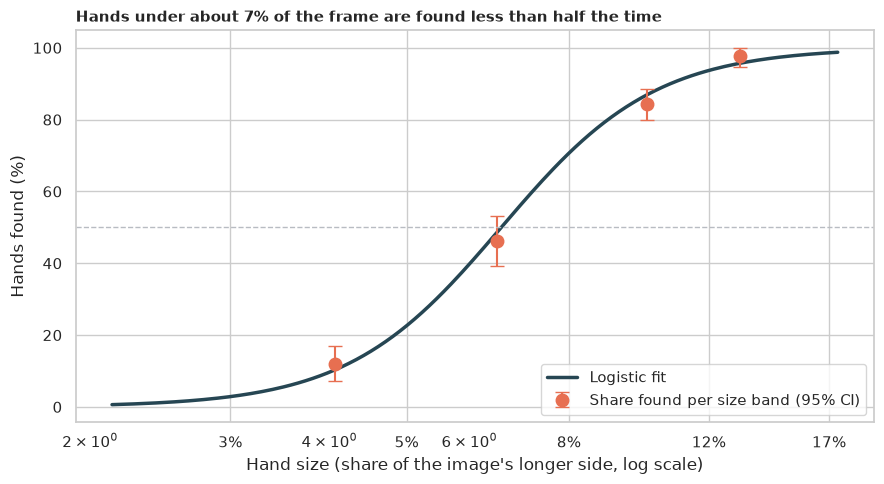

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
grid = np.linspace(np.log2(hands["size"].min()), np.log2(hands["size"].max()), 200)
ax.plot(
    2**grid * 100,
    logit.predict(sm.add_constant(pd.Series(grid, name="size"))) * 100,
    color=NAVY,
    lw=2.5,
    label="Logistic fit",
)
centres = [hands.loc[hands["size band"] == n, "size"].median() * 100 for n in SIZE_NAMES]
ax.errorbar(
    centres,
    bands["found"] * 100,
    yerr=[(bands["found"] - bands["ci_low"]) * 100, (bands["ci_high"] - bands["found"]) * 100],
    fmt="o",
    color=ORANGE,
    capsize=5,
    ms=9,
    label="Share found per size band (95% CI)",
)
ax.axhline(50, color=GREY, ls="--", lw=1)
ax.set_xscale("log")
ax.set_xticks([3, 5, 8, 12, 17], ["3%", "5%", "8%", "12%", "17%"])
ax.set_xlabel("Hand size (share of the image's longer side, log scale)")
ax.set_ylabel("Hands found (%)")
ax.set_title(
    f"Hands under about {half:.0%} of the frame are found less than half the time",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(OUT_DIR / "01_hand_size.png", dpi=150)
plt.show()

**How to read this:**

- **Size decides almost everything:** the share found is **11.9%** (CI 7.2% to 17.1%) for hands under 5% of the frame, **46.1%** (39.3% to 53.1%) for 5-8%, **84.3%** (79.8% to 88.4%) for 8-12% and **97.7%** (94.7% to 100%) above 12%.
- **Each doubling of the hand's size multiplies the odds of being found by 22.4** (95% CI 15.1 to 33.2; p = 2e-54), and a hand is found half the time at about **6.6%** of the longer side of the image. **We reject H₀.** The Spearman correlation between size and overlap is **+0.65**.
- **The practical rule:** keep the hand above about 12% of the frame and it is found almost every time; below 5% it is nearly invisible. A user who steps back from the webcam can drop below the cliff.

## 8. H3: can zooming in find the missed hands?

*What:* the palm detector needs the hand to fill enough of its view, so we give it a closer look: besides the whole picture, run it on a **2 x 2 grid of overlapping tiles** (each 60% of the picture) or a **3 x 3 grid** (each 45%), merge duplicate hands, and see which hands are found. We compare with the whole-image run using the exact McNemar test, and time each strategy. *Why:* this uses nothing except the same model and a little code, so it shows whether the misses are about the *model* or about the *view*.

In [7]:
tiled_dets, tiled_ms = {}, {}
for name, (n, frac) in TILE_SETTINGS.items():
    tiled_dets[name], tiled_ms[name] = run_strategy(
        name, lambda im, n=n, frac=frac: detect_tiled(landmarker, im, n, frac)
    )
rows, found_sets = [], {"Whole image": hands["found_full"].to_numpy()}
for name, dets in tiled_dets.items():
    ious = [best_match(box, d)[0] for box, d in zip(hands["box"], dets, strict=True)]
    hands[f"iou_{name}"] = ious
    found_sets[name] = np.array(ious) >= IOU_MATCH
timing = {"Whole image": full_ms, **tiled_ms}
for name, flags in found_sets.items():
    by_band = [flags[hands["size band"] == b].mean() for b in SIZE_NAMES]
    rows.append(
        {
            "strategy": name,
            "found": flags.mean(),
            **{b: v for b, v in zip(SIZE_NAMES, by_band, strict=True)},
            "ms per image": timing[name],
        }
    )
tiling = pd.DataFrame(rows).set_index("strategy")
print(tiling.round(3).to_string())
base = found_sets["Whole image"]
for name in TILE_SETTINGS:
    ok = found_sets[name]
    mc = mcnemar(
        [
            [int((ok & base).sum()), int((ok & ~base).sum())],
            [int((~ok & base).sum()), int((~ok & ~base).sum())],
        ],
        exact=True,
    )
    print(
        f"{name} vs whole image: finds {int((ok & ~base).sum())} hands the whole image misses, "
        f"misses {int((~ok & base).sum())} it finds; exact McNemar p = {fmt_p(mc.pvalue)}"
    )

2x2 tiles: 461 images, 111 ms per image (including reading the file)


3x3 tiles: 461 images, 185 ms per image (including reading the file)
             found  under 5%   5-8%  8-12%  over 12%  ms per image
strategy                                                          
Whole image  0.622     0.119  0.461  0.843     0.977        30.477
2x2 tiles    0.767     0.483  0.668  0.889     0.983       110.517
3x3 tiles    0.793     0.597  0.705  0.864     0.988       185.030
2x2 tiles vs whole image: finds 123 hands the whole image misses, misses 0 it finds; exact McNemar p = 1.9e-37
3x3 tiles vs whole image: finds 145 hands the whole image misses, misses 0 it finds; exact McNemar p = 4.5e-44


**How to read this:**

- **Zooming in finds many more hands:** the share found rises from **62.2%** (whole image) to **76.7%** (2 x 2 tiles) and **79.3%** (3 x 3 tiles).
- **It gains many hands:** the 2 x 2 grid finds **123** hands the whole image misses (exact McNemar p = 2e-37) and the 3 x 3 grid finds **145** (p = 5e-44). The tiled runs also include the whole-image run, so they cannot lose a hand by construction (the 0 hands lost is guaranteed, not a finding); the question is how many they gain. **We reject H₀.**
- **The gain is in the small hands:** hands under 5% of the frame go from **11.9% to 48.3%** (2 x 2) and **59.7%** (3 x 3); the 5-8% band from 46.1% to **66.8%** and **70.5%**. Large hands barely change (over 12%: 97.7% to 98.3% and 98.8%).
- **It costs time:** **30 ms** for the whole image, **111 ms** for 2 x 2 and **185 ms** for 3 x 3 per photograph (including reading the file). Only the whole-image run fits in the 33 ms budget of a 30-frames-per-second webcam on one CPU process.
- The figure shows hands that were found in the whole image, hands rescued by tiles, and hands still missed. The hands missed by everything are often half hidden, in gloves, holding things or at an angle.

## 9. H4: lowering the bar, or zooming in?

*What:* there is a second way to find more hands: lower the model's **confidence bar** (0.1, 0.3, 0.5, 0.7, 0.9). The price is false alarms. To measure them we need photographs with **no hands in them**, so we **paint out every labelled hand** (with OpenCV's inpainting) in all 461 photographs and count the hands MediaPipe still reports. We then plot the share found against false alarms per photograph for the five confidence settings, and for the two tile grids at confidence 0.5. *Why:* "finds more hands" means little without "and invents how many?".

In [8]:
NEG_DIR = DATA_DIR / "negatives"
NEG_DIR.mkdir(exist_ok=True)
negatives = []
for name, group in hands.groupby("image"):
    target = NEG_DIR / f"{name}.png"
    if not target.exists():
        rgb = read_rgb(group["path"].iloc[0])
        mask = np.zeros(rgb.shape[:2], np.uint8)
        for box in group["box"]:
            pad = 0.3 * max(box[2] - box[0], box[3] - box[1])
            x0, y0 = max(int(box[0] - pad), 0), max(int(box[1] - pad), 0)
            mask[y0 : int(box[3] + pad), x0 : int(box[2] + pad)] = 255
        cv2.imwrite(
            str(target),
            cv2.cvtColor(cv2.inpaint(rgb, mask, 5, cv2.INPAINT_TELEA), cv2.COLOR_RGB2BGR),
        )
    negatives.append(target)
print(
    f"{len(negatives)} photographs with every labelled hand painted out "
    "(any hand reported in them is a false alarm)"
)


def false_alarms(fn) -> float:
    """Average number of hands reported per photograph with the labelled hands painted out."""
    return float(np.mean([len(fn(read_rgb(p))) for p in negatives]))


sweep = []
for conf in THRESHOLDS:
    lm = make_landmarker(conf)
    found = np.array(
        [
            best_match(box, detect(lm, read_rgb(path)))[0] >= IOU_MATCH
            for path, box in zip(hands["path"], hands["box"], strict=True)
        ]
    )
    fa = false_alarms(lambda im, lm=lm: detect(lm, im))
    sweep.append(
        {
            "setting": f"whole image, confidence {conf}",
            "found": found.mean(),
            "false alarms per photo": fa,
        }
    )
    print(f"  confidence {conf}: found {found.mean():.1%}, false alarms {fa:.3f} per photo")
for name, (n, frac) in TILE_SETTINGS.items():
    fa = false_alarms(lambda im, n=n, frac=frac: detect_tiled(landmarker, im, n, frac))
    sweep.append(
        {
            "setting": f"{name}, confidence 0.5",
            "found": found_sets[name].mean(),
            "false alarms per photo": fa,
        }
    )
    print(
        f"  {name}, confidence 0.5: found {found_sets[name].mean():.1%}, "
        f"false alarms {fa:.3f} per photo"
    )
sweep = pd.DataFrame(sweep)

461 photographs with every labelled hand painted out (any hand reported in them is a false alarm)


  confidence 0.1: found 71.4%, false alarms 0.842 per photo


  confidence 0.3: found 66.9%, false alarms 0.304 per photo


  confidence 0.5: found 62.2%, false alarms 0.152 per photo


  confidence 0.7: found 56.0%, false alarms 0.054 per photo


  confidence 0.9: found 32.3%, false alarms 0.011 per photo


  2x2 tiles, confidence 0.5: found 76.7%, false alarms 0.440 per photo


  3x3 tiles, confidence 0.5: found 79.3%, false alarms 0.607 per photo


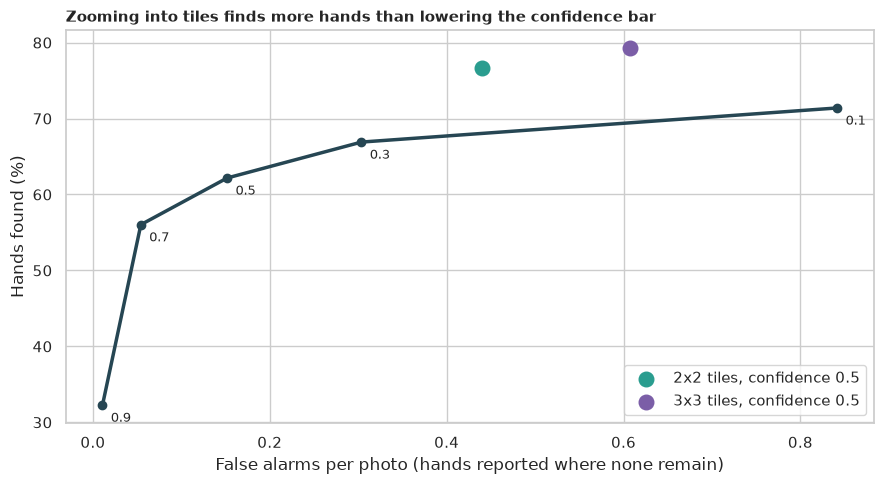

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
whole = sweep[sweep["setting"].str.startswith("whole")]
ax.plot(whole["false alarms per photo"], whole["found"] * 100, marker="o", color=NAVY, lw=2.5)
for conf, (_, r) in zip(THRESHOLDS, whole.iterrows(), strict=True):
    ax.annotate(
        f"{conf}",
        (r["false alarms per photo"], r["found"] * 100),
        textcoords="offset points",
        xytext=(6, -12),
        fontsize=9,
    )
for (_, r), color in zip(
    sweep[~sweep["setting"].str.startswith("whole")].iterrows(), [TEAL, PURPLE], strict=True
):
    ax.scatter(
        r["false alarms per photo"],
        r["found"] * 100,
        s=110,
        color=color,
        zorder=3,
        label=r["setting"],
    )
ax.set_xlabel("False alarms per photo (hands reported where none remain)")
ax.set_ylabel("Hands found (%)")
ax.set_title(
    "Zooming into tiles finds more hands than lowering the confidence bar",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(OUT_DIR / "02_tradeoff.png", dpi=150)
plt.show()

**How to read this:**

- **Lowering the bar buys hands at a rising price:** at confidence 0.9 it finds **32.3%** of the hands with **0.011** false alarms per photograph; at 0.7 **56.0%** with 0.054; at the default 0.5 **62.2%** with **0.152**; at 0.3 **66.9%** with 0.304; and at 0.1 **71.4%** with **0.842**.
- **Tiles beat the confidence knob:** 2 x 2 tiles at confidence 0.5 find **76.7%** with **0.44** false alarms per photograph, more hands than confidence 0.1 (71.4%) with about half the false alarms (0.84). The 3 x 3 grid finds **79.3%** with 0.61.
- **No setting is free:** every gain brings false alarms. The best choice depends on the cost of a miss against the cost of a false alarm (a volume knob that sometimes jumps is more annoying than one that sometimes ignores you).
- **Read the false alarms with care:** a few "false alarms" may be hands we did not label (a third person, a doll), and the painted-out patches are not natural. Compare the settings with each other rather than reading the exact values.

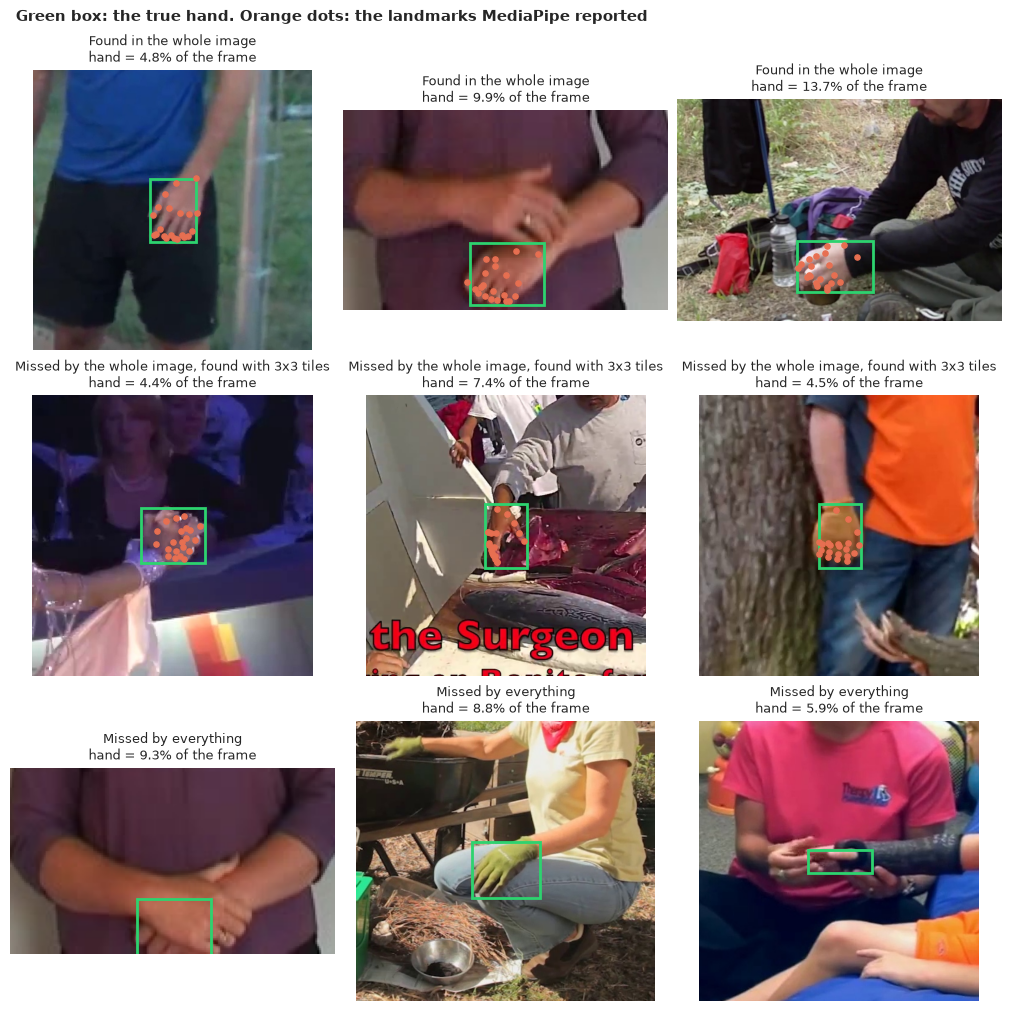

In [10]:
def draw_example(ax: plt.Axes, k: int, dets: list[dict], title: str) -> None:
    """Shows the true hand (green box), the landmarks MediaPipe found (orange) and its context."""
    rgb = read_rgb(hands["path"].iloc[k])
    box = hands["box"].iloc[k]
    cx, cy, half = (
        (box[0] + box[2]) / 2,
        (box[1] + box[3]) / 2,
        2.2 * max(box[2] - box[0], box[3] - box[1]),
    )
    x0, x1 = int(max(cx - half, 0)), int(min(cx + half, rgb.shape[1]))
    y0, y1 = int(max(cy - half, 0)), int(min(cy + half, rgb.shape[0]))
    ax.imshow(rgb[y0:y1, x0:x1], extent=(x0, x1, y1, y0))
    ax.add_patch(
        plt.Rectangle(box[:2], box[2] - box[0], box[3] - box[1], fill=False, ec="#2dd36f", lw=2)
    )
    for d in dets:
        if iou(box, hull(d["pts"])) >= IOU_MATCH:
            ax.scatter(*d["pts"].T, s=14, color=ORANGE)
    ax.set_title(title, fontsize=9)
    ax.axis("off")


rescued = np.flatnonzero(~found_sets["Whole image"] & found_sets["3x3 tiles"])
still_missed = np.flatnonzero(~found_sets["3x3 tiles"])
whole_ok = np.flatnonzero(found_sets["Whole image"])
picks = [
    ("Found in the whole image", rng.choice(whole_ok, 3, replace=False), full_dets),
    (
        "Missed by the whole image, found with 3x3 tiles",
        rng.choice(rescued, 3, replace=False),
        tiled_dets["3x3 tiles"],
    ),
    ("Missed by everything", rng.choice(still_missed, 3, replace=False), tiled_dets["3x3 tiles"]),
]
fig, axes = plt.subplots(3, 3, figsize=(10, 10), layout="constrained")
for row, (name, ks, dets) in zip(axes, picks, strict=True):
    for ax, k in zip(row, ks, strict=True):
        draw_example(ax, k, dets[k], f"{name}\nhand = {hands['size'].iloc[k]:.1%} of the frame")
fig.suptitle(
    "Green box: the true hand. Orange dots: the landmarks MediaPipe reported",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.savefig(OUT_DIR / "03_examples.png", dpi=130)
plt.show()

## 10. H5: how accurate are the landmarks?

*What:* for every hand found in the whole-image run, the distance from each of the 21 landmarks to the hand-labelled keypoint, as a share of the hand's size. We compare fingertips with finger bases (paired Wilcoxon), check the correlation with hand size, and check the **left/right label** MediaPipe reports. *Why:* a hand-controlled interface mostly uses fingertips, which are exactly the points that move the most.

In [11]:
LANDMARKS = ["wrist"] + [
    f"{f} {j}"
    for f in ("thumb", "index", "middle", "ring", "pinky")
    for j in ("base", "joint", "joint 2", "tip")
]
errors = []  # normalised error of the 21 landmarks for each found hand (whole image run)
labels_ok, labels_flipped, n_labelled = 0, 0, 0
for k in np.flatnonzero(found_sets["Whole image"]):
    _, det = best_match(hands["box"].iloc[k], full_dets[k])
    size = max(np.ptp(hands["pts"].iloc[k][:, 0]), np.ptp(hands["pts"].iloc[k][:, 1]))
    errors.append(np.linalg.norm(det["pts"] - hands["pts"].iloc[k], axis=1) / size)
    n_labelled += 1
    labels_ok += det["label"].lower() == hands["side"].iloc[k]
errors = np.array(errors)
per_hand = errors.mean(1)
print(f"Found hands: {len(errors)}; landmark error as a share of the hand's size:")
print(
    f"  per hand: median {np.median(per_hand):.1%} (middle half {np.percentile(per_hand, 25):.1%} "
    f"to {np.percentile(per_hand, 75):.1%}; worst tenth above {np.percentile(per_hand, 90):.1%})"
)
by_size = hands.loc[found_sets["Whole image"], "size"].to_numpy()
rho = stats.spearmanr(by_size, per_hand)
print(f"  Spearman correlation with hand size: {rho.statistic:+.2f}, p = {fmt_p(rho.pvalue)}")
tips, bases = errors[:, [4, 8, 12, 16, 20]].mean(1), errors[:, [1, 5, 9, 13, 17]].mean(1)
wil = stats.wilcoxon(tips, bases)
print(
    f"  fingertips {np.median(tips):.1%} vs finger bases {np.median(bases):.1%} "
    f"(paired Wilcoxon p = {fmt_p(wil.pvalue)}; fingertips worse in {(tips > bases).mean():.0%} "
    "of hands)"
)
accuracy = labels_ok / n_labelled
bt = stats.binomtest(labels_ok, n_labelled, 0.5)
print(
    f"Left/right label as reported: right for {labels_ok} of {n_labelled} hands = {accuracy:.1%} "
    f"(95% CI {bt.proportion_ci().low:.1%} to {bt.proportion_ci().high:.1%}); "
    f"flipped it would be right {1 - accuracy:.1%} of the time"
)

Found hands: 526; landmark error as a share of the hand's size:
  per hand: median 7.0% (middle half 5.1% to 9.9%; worst tenth above 14.8%)
  Spearman correlation with hand size: -0.43, p = 4.7e-25
  fingertips 8.1% vs finger bases 5.7% (paired Wilcoxon p = 1.6e-29; fingertips worse in 70% of hands)
Left/right label as reported: right for 502 of 526 hands = 95.4% (95% CI 93.3% to 97.1%); flipped it would be right 4.6% of the time


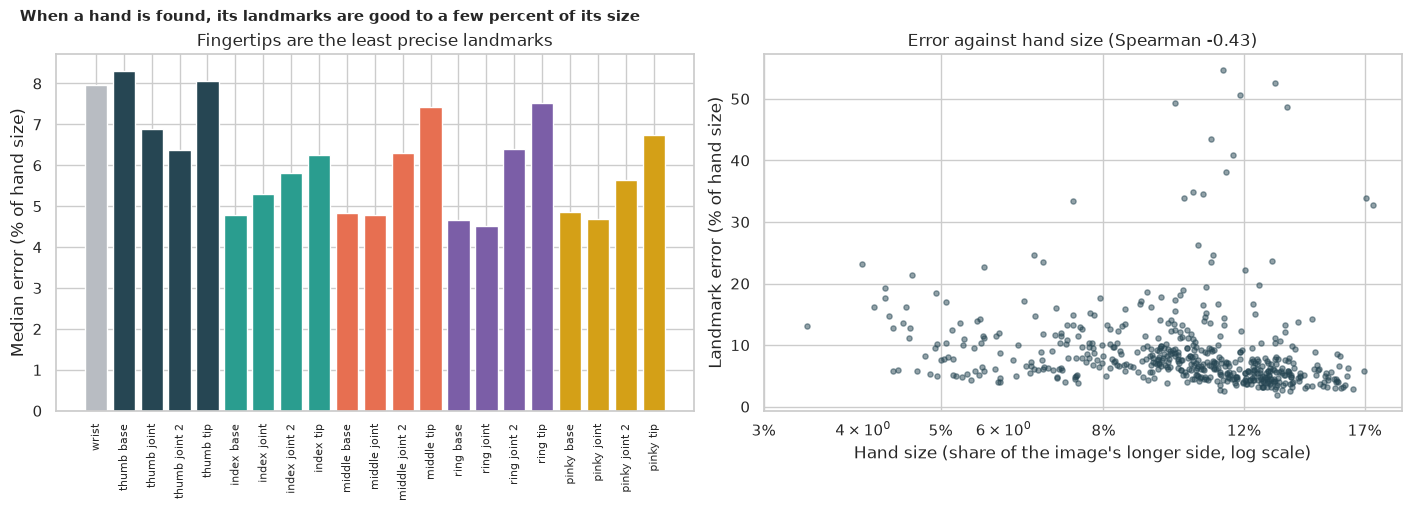

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout="constrained")
medians = np.median(errors, axis=0) * 100
colors = [GREY] + [c for c in (NAVY, TEAL, ORANGE, PURPLE, "#d4a017") for _ in range(4)]
axes[0].bar(range(21), medians, color=colors)
axes[0].set_xticks(range(21), LANDMARKS, rotation=90, fontsize=8)
axes[0].set_ylabel("Median error (% of hand size)")
axes[0].set_title("Fingertips are the least precise landmarks")
axes[1].scatter(by_size * 100, per_hand * 100, s=14, alpha=0.5, color=NAVY)
axes[1].set_xscale("log")
axes[1].set_xticks([3, 5, 8, 12, 17], ["3%", "5%", "8%", "12%", "17%"])
axes[1].set_xlabel("Hand size (share of the image's longer side, log scale)")
axes[1].set_ylabel("Landmark error (% of hand size)")
axes[1].set_title(f"Error against hand size (Spearman {rho.statistic:+.2f})")
fig.suptitle(
    "When a hand is found, its landmarks are good to a few percent of its size",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.savefig(OUT_DIR / "04_landmark_error.png", dpi=150)
plt.show()

**How to read this:**

- **The landmarks are good to a few percent of the hand's size:** per hand, the median error is **7.0%** (middle half 5.1% to 9.9%); the worst tenth is above **14.8%**.
- **Fingertips are less accurate than the finger bases:** **8.1%** against **5.7%** (paired Wilcoxon p = 2e-29), and worse in **70%** of hands. **We reject H₀.** This matters for gestures that rely on fingertips (a pinch), as the next project examines.
- **Smaller hands have larger relative errors:** Spearman **-0.43** (p = 5e-25) between size and error. A landmark is placed to within a few pixels at best, which is a bigger share of a small hand.
- **The left/right label is reliable:** **502 of 526** found hands (**95.4%**, 95% CI 93.3% to 97.1%) get the correct side. We did not investigate the 4.6% of errors.

## 11. 🎯 Takeaways

1. **MediaPipe finds six hands in ten in everyday photographs** (62.2%, CI 58.4% to 66.3%), not nine in ten. Webcam demos show the easy case of a close, front-facing hand.
2. **Size is destiny:** each doubling of a hand's size multiplies the odds of being found by 22. Hands above 12% of the frame are found 98% of the time; under 5%, 12%.
3. **Zooming in is the cheapest fix:** a 2 x 2 grid of tiles raises the share found from 62% to 77% (123 hands gained) at about 3.6 times the run time.
4. **Tiles beat a lower confidence bar:** more hands (76.7% against 71.4%) for about half the false alarms (0.44 against 0.84 per photograph).
5. **Landmarks are good, fingertips less so:** median error 7% of the hand's size, fingertips 8.1% against 5.7% for the finger bases.
6. **Know your distance:** a tracker is tuned for a hand size as much as for a hand.

## 12. ⚠️ Limitations

- **Photographs, not webcam video.** The hands come from everyday photographs and sign-language frames; a real webcam session has a hand held up and moving, and the tracker's video mode follows a hand between frames.
- **One hand per annotation, and two per photograph at most.** Unlabelled hands count against the detector in H4.
- **The IoU ≥ 0.5 rule is a choice,** and the box around landmarks is not the same as a human-drawn box.
- **Inpainted negatives are artificial;** compare false-alarm rates with each other, not as absolute numbers.
- **The tile settings (2 x 2 at 60%, 3 x 3 at 45%) were picked once;** other grids may do better, and we did not tune them.
- **Speed is measured on one CPU process,** including reading each image, and will differ on other machines.
- **One model:** the default float16 MediaPipe hand model; other models and the full model variant were not tested.
- **No fairness check:** the annotated hands were not examined across skin tones, ages or sizes of hands, so detection rates may differ across groups.
- **Handedness depends on the convention:** the labels agree with the dataset in this setup, but we did not test a mirrored camera image, which many webcam apps use and which may flip them.